# RQ2 real-LLM validation attempt: interrupted

Pinned creator TIB `valid` cohort (20 DOI). Qwen2.5-1.5B-Instruct revision `989aa7980e4cf806f80c7fef2b1adb7bc71aa306` generated **5 paired outputs** before the local RTX 4050 reported `GPU is lost` and the machine crashed. The other 15 DOI are `not_run`. This notebook reads saved JSON only and uses CPU; it does not load the LLM or access sealed `test`. Abstracts are noisy creator targets; ROUGE-L is agreement with them, not factuality.

In [1]:
import json, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
root=Path.cwd()
p=root/'experiments/outputs/diagnostic/rq2_valid_controlled_qwen/automatic_evaluation_interrupted.json'
d=json.loads(p.read_text(encoding='utf-8'))
assert d['split']=='valid' and d['test_content_accessed'] is False
assert d['n_declared']==20 and d['n_completed']==5
print('Model:',d['model'])
print('Completed:',d['n_completed'],'/20; not run:',d['n_declared']-d['n_completed'])
print('Receipt:',p)

Model: Qwen/Qwen2.5-1.5B-Instruct@989aa7980e4cf806f80c7fef2b1adb7bc71aa306
Completed: 5 /20; not run: 15
Receipt: C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\multimodal-lecture-summarizer\experiments\outputs\diagnostic\rq2_valid_controlled_qwen\automatic_evaluation_interrupted.json


In [2]:
complete=[r for r in d['rows'] if r['generation_status']=='completed']
rows=[]
for r in complete:
 rows.append({'DOI':r['doi'].split()[0], 'abstract_words':r['abstract_words'], 'reference_screen':r['reference_screen'], 'source_tokens':r['source_tokens'], 'prompt_imbalance':r['prompt_imbalance_tokens'], 'S1_ROUGE_L':r['arms']['S1']['rouge_l_abstract_proxy'], 'S3_ROUGE_L':r['arms']['S3']['rouge_l_abstract_proxy'], 'S3_minus_S1':r['delta_s3_minus_s1']['rouge_l_abstract_proxy']})
df=pd.DataFrame(rows)
display(df.round(4))
not_run=[{'DOI':r['doi'].split()[0], 'status':r['generation_status'], 'reason':r.get('reason')} for r in d['rows'] if r['generation_status']!='completed']
display(pd.DataFrame(not_run))

,DOI,abstract_words,reference_screen,source_tokens,prompt_imbalance,S1_ROUGE_L,S3_ROUGE_L,S3_minus_S1
0,10.5446/45978,74,candidate_unverified,2595,4,0.1630,0.1769,0.0139
1,10.5446/49509,19,candidate_unverified,3073,1,0.1609,0.1087,-0.0522
2,10.5446/48908,22,candidate_unverified,2435,1,0.2250,0.1263,-0.0987
3,10.5446/49247,22,candidate_unverified,1171,10,0.1053,0.1591,0.0538
4,10.5446/49452,14,candidate_unverified,3494,226,0.1628,0.1905,0.0277


,DOI,status,reason
0,10.5446/50943,not_run,GPU device lost during validation run; process...
1,10.5446/46066,not_run,GPU device lost during validation run; process...
2,10.5446/16294,not_run,GPU device lost during validation run; process...
3,10.5446/38319,not_run,GPU device lost during validation run; process...
4,10.5446/20846,not_run,GPU device lost during validation run; process...
5,10.5446/38638,not_run,GPU device lost during validation run; process...
6,10.5446/14078,not_run,GPU device lost during validation run; process...
7,10.5446/55669,not_run,GPU device lost during validation run; process...
8,10.5446/35254,not_run,GPU device lost during validation run; process...
9,10.5446/19217,not_run,GPU device lost during validation run; process...


Paired ROUGE-L S3−S1: -0.0111 95% CI: [-0.06412, 0.03291] n= 5


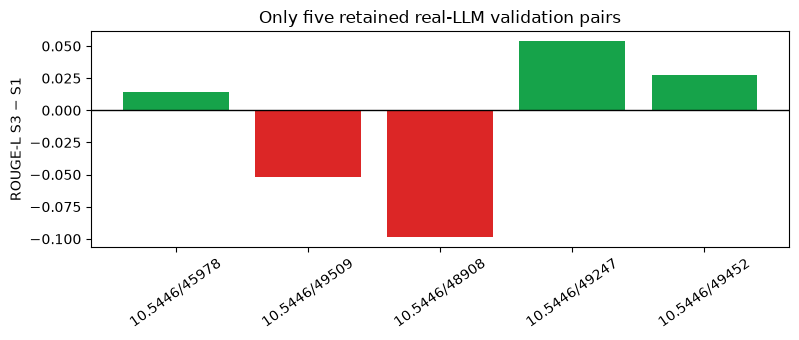

In [3]:
x=d['paired_rouge']
print('Paired ROUGE-L S3−S1:',round(x['mean_s3_minus_s1'],5),'95% CI:',[round(z,5) for z in x['ci95']],'n=',x['n'])
fig,ax=plt.subplots(figsize=(8,3.5))
ax.bar(df.DOI,df.S3_minus_S1,color=['#16a34a' if v>=0 else '#dc2626' for v in df.S3_minus_S1])
ax.axhline(0,color='black',linewidth=1); ax.set(ylabel='ROUGE-L S3 − S1',title='Only five retained real-LLM validation pairs')
ax.tick_params(axis='x',rotation=35); fig.tight_layout(); display(fig); plt.close(fig)

## Interpretation

This shortest-first five-item subset has a wide interval around zero. It cannot establish a positive or negative RQ2 effect. The run stopped because the local GPU/device failed; the 15 missing talks are recorded, not silently omitted. Source lexical overlap is unavailable in the cached-abstract evaluation. Continue on stable compute with a documented device/backend, then compare all eligible paired talks. No blinded or other human scoring is needed.